# Softmax Regression (Multi-class) - Stochastic Gradient Descent
Dataset: [Mobile Price Classification](https://www.kaggle.com/datasets/iabhishekofficial/mobile-price-classification) from Kaggle (`train.csv`).

Softmax regression is logistic regression for more than 2 classes (here 4 price ranges). We train it with **Stochastic Gradient Descent** and use the validation data to check overfitting.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

## Load the data

In [2]:
data = pd.read_csv("../data/train.csv")
print(data.shape)
print(data.isnull().sum().sum())
data.head()

(2000, 21)
0

,battery_power,blue,clock_speed,dual_sim,fc,four_g,int_memory,m_dep,mobile_wt,n_cores,pc,px_height,px_width,ram,sc_h,sc_w,talk_time,three_g,touch_screen,wifi,price_range
0,842,0,2.2,0,1,0,7,0.6,188,2,2,20,756,2549,9,7,19,0,0,1,1
1,1021,1,0.5,1,0,1,53,0.7,136,3,6,905,1988,2631,17,3,7,1,1,0,2
2,563,1,0.5,1,2,1,41,0.9,145,5,6,1263,1716,2603,11,2,9,1,1,0,2
3,615,1,2.5,0,0,0,10,0.8,131,6,9,1216,1786,2769,16,8,11,1,0,0,2
4,1821,1,1.2,0,13,1,44,0.6,141,2,14,1208,1212,1411,8,2,15,1,1,0,1


In [3]:
# price_range: 0 = low cost, 1 = medium, 2 = high, 3 = very high
print(data["price_range"].value_counts().sort_index())

price_range
0    500
1    500
2    500
3    500
Name: count, dtype: int64

## Split the data (train / validation / test)

In [4]:
# features and labels
X_raw = data.drop("price_range", axis=1).values
y = data["price_range"].values
feature_names = data.drop("price_range", axis=1).columns

# split: 60% train, 20% validation, 20% test
np.random.seed(42)
indices = np.random.permutation(len(y))
n_train = int(0.6 * len(y))
n_val = int(0.2 * len(y))
train_idx = indices[:n_train]
val_idx = indices[n_train:n_train + n_val]
test_idx = indices[n_train + n_val:]
print("train:", len(train_idx), " validation:", len(val_idx), " test:", len(test_idx))

train: 1200  validation: 400  test: 400

## Prepare the data

In [5]:
# scaling (mean and std from the train data only)
mean = X_raw[train_idx].mean(axis=0)
std = X_raw[train_idx].std(axis=0)
X_scaled = (X_raw - mean) / std

# add the bias column (ones)
X = np.ones((len(y), 21))
X[:, 1:] = X_scaled

# one-hot labels: 0 -> [1,0,0,0], 1 -> [0,1,0,0], 2 -> [0,0,1,0], 3 -> [0,0,0,1]
Y = np.zeros((len(y), 4))
for i in range(len(y)):
    Y[i, y[i]] = 1

X_train, Y_train, y_train = X[train_idx], Y[train_idx], y[train_idx]
X_val, Y_val, y_val = X[val_idx], Y[val_idx], y[val_idx]
X_test, Y_test, y_test = X[test_idx], Y[test_idx], y[test_idx]
print(X_train.shape, Y_train.shape)

(1200, 21) (1200, 4)

## Functions
`softmax` turns the scores into probabilities for the 4 classes (they add up to 1). The loss is cross-entropy.

In [6]:
def softmax(z):
    z = z - z.max(axis=1, keepdims=True)   # for numerical stability
    exp_z = np.exp(z)
    return exp_z / exp_z.sum(axis=1, keepdims=True)

def predict_proba(X, W):
    return softmax(X.dot(W))

def predict(X, W):
    return np.argmax(predict_proba(X, W), axis=1)

def compute_loss(X, Y, W):
    P = np.clip(predict_proba(X, W), 1e-15, 1)   # to avoid log(0)
    return -np.mean(np.sum(Y * np.log(P), axis=1))

def compute_gradient(X, Y, W):
    m = len(X)
    P = predict_proba(X, W)
    return (1 / m) * X.T.dot(P - Y)

## Metrics

In [7]:
def evaluate(y_true, y_pred, n_classes=4):
    accuracy = np.mean(y_true == y_pred)

    # precision, recall and f1 for every class, then the average (macro)
    precisions, recalls, f1s = [], [], []
    for c in range(n_classes):
        TP = np.sum((y_pred == c) & (y_true == c))
        FP = np.sum((y_pred == c) & (y_true != c))
        FN = np.sum((y_pred != c) & (y_true == c))
        precision = TP / (TP + FP) if TP + FP > 0 else 0
        recall = TP / (TP + FN) if TP + FN > 0 else 0
        f1 = 2 * precision * recall / (precision + recall) if precision + recall > 0 else 0
        precisions.append(precision)
        recalls.append(recall)
        f1s.append(f1)
    return accuracy, np.mean(precisions), np.mean(recalls), np.mean(f1s)

def confusion_matrix(y_true, y_pred, n_classes=4):
    cm = np.zeros((n_classes, n_classes), dtype=int)
    for i in range(len(y_true)):
        cm[y_true[i], y_pred[i]] += 1
    return cm

## Stochastic Gradient Descent (SGD)
We update W after every single sample (one row at a time), in random order.

In [8]:
lr = 0.01
n_epochs = 100
m = len(y_train)

W = np.zeros((21, 4))
train_loss = []
val_loss = []

for epoch in range(n_epochs):
    order = np.random.permutation(m)
    for i in order:
        xi = X_train[i:i+1]
        yi = Y_train[i:i+1]
        gradient = compute_gradient(xi, yi, W)
        W = W - lr * gradient
    train_loss.append(compute_loss(X_train, Y_train, W))
    val_loss.append(compute_loss(X_val, Y_val, W))

## Results

In [9]:
train_acc = np.mean(predict(X_train, W) == y_train)
val_acc = np.mean(predict(X_val, W) == y_val)
print("train loss:", round(train_loss[-1], 4), " validation loss:", round(val_loss[-1], 4))
print("train accuracy:", round(train_acc, 4), " validation accuracy:", round(val_acc, 4))
print()

y_pred = predict(X_test, W)

train loss: 0.1496  validation loss: 0.1679
train accuracy: 0.9792  validation accuracy: 0.9425

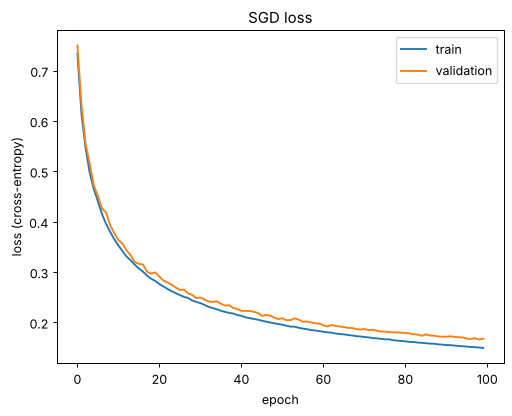

In [10]:
plt.plot(train_loss, label="train")
plt.plot(val_loss, label="validation")
plt.xlabel("epoch")
plt.ylabel("loss (cross-entropy)")
plt.title("SGD loss")
plt.legend()
plt.show()

In [11]:
accuracy, precision, recall, f1 = evaluate(y_test, y_pred)
print("Test Accuracy:", round(accuracy, 4))
print("Test Precision:", round(precision, 4))
print("Test Recall:", round(recall, 4))
print("Test F1:", round(f1, 4))

Test Accuracy: 0.9675
Test Precision: 0.9674
Test Recall: 0.9684
Test F1: 0.9677

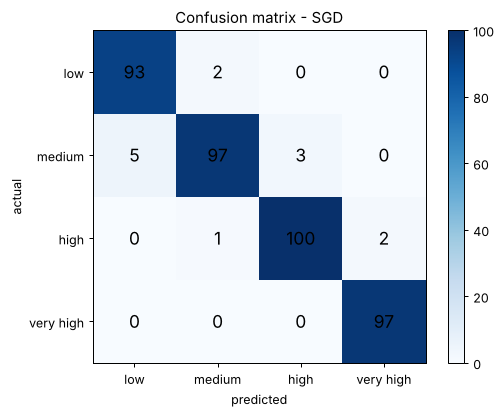

In [12]:
cm = confusion_matrix(y_test, y_pred)

plt.imshow(cm, cmap="Blues")
for i in range(4):
    for j in range(4):
        plt.text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
plt.xticks([0, 1, 2, 3], ["low", "medium", "high", "very high"])
plt.yticks([0, 1, 2, 3], ["low", "medium", "high", "very high"])
plt.xlabel("predicted")
plt.ylabel("actual")
plt.title("Confusion matrix - SGD")
plt.colorbar()
plt.show()

## Conclusion
SGD makes many cheap updates (one per sample), so it learns fast but the loss is a bit noisy.